### Experimental setup and adjustments

- **Sizes:** operations use n = 1,000 / 5,000 / 10,000 / 25,000. Insertion sort uses n = 1,000 / 2,000 / 4,000 / 8,000 instead, because pure-Python insertion sort is O(n²) and 25,000 elements would take about a minute per run (6 input/structure combinations × 7 runs).
- **Timing:** `time.perf_counter()`, median of 7 runs. Garbage collection is disabled during each timed region. Very fast operations (read middle, binary search) are repeated inside the timed region and divided, to beat timer resolution.
- **Same logical data:** both structures are built from the same list of `MaintenanceRequest` objects (IDs 1000 to 1000+n-1).
- **Setup is untimed and bypasses `append`:** `append`/`push`/`insertAt` run an O(n) duplicate check, so building 25,000 items through them would cost about 300 million comparisons. Lists are built directly, and only the operation under test is timed.
- **Spare capacity:** the array is built with capacity 2n so that no resize lands inside a timed insert.
- **Sort input:** priorities are distinct (0 to n-1) so sorted and reverse inputs are clean best and worst cases. With the real 1 to 4 scale, nearly everything would be a tie at large n.

In [7]:
class MaintenanceRequest:

    def __init__(self, request_id, building, category, priority, reported_time, status):
        self.request_id = request_id
        self.building = building
        self.category = category
        self.priority = priority
        self.reported_time = reported_time
        self.status = status

    def __str__(self):
        return (f"#{self.request_id} {self.building} {self.category} "
                f"P{self.priority} t={self.reported_time} {self.status}")


class ArrayRequestList:

    def __init__(self, initial_capacity=4):
        if initial_capacity < 1:
            raise ValueError("initial_capacity must be at least 1")
        self.capacity = initial_capacity
        self.data = [None] * self.capacity
        self.size = 0

    def linearSearchById(self, request_id):
      for i in range(self.size):
          if self.data[i].request_id == request_id:
              return i
      return -1

    def _resize(self, new_capacity):

        new_data = [None] * new_capacity
        for i in range(self.size):
            new_data[i] = self.data[i]
        self.data = new_data
        self.capacity = new_capacity

    def insertAt(self, index, request):

        if index < 0 or index > self.size:
            raise IndexError("index out of range")


        for i in range(self.size):
            if self.data[i].request_id == request.request_id:
                raise ValueError("duplicate request_id")


        if self.size == self.capacity:
            self._resize(self.capacity * 2)


        i = self.size
        while i > index:
            self.data[i] = self.data[i - 1]
            i = i - 1


        self.data[index] = request
        self.size = self.size + 1

    def push(self, request):
        self.insertAt(0, request)

    def append(self, request):
        self.insertAt(self.size, request)

    def count(self):
        return self.size

    def getAt(self, index):
        if index < 0 or index >= self.size:
            raise IndexError("index out of range")
        return self.data[index]

    def removeAt(self, index):
        if index < 0 or index >= self.size:
            raise IndexError("index out of range")
        removed = self.data[index]


        for i in range(index, self.size - 1):
            self.data[i] = self.data[i + 1]

        self.data[self.size - 1] = None
        self.size = self.size - 1
        return removed

    def findById(self, request_id):
        for i in range(self.size):
            if self.data[i].request_id == request_id:
                return self.data[i]
        return None

    def __len__(self):
        return self.size

    def __str__(self):
        if self.size == 0:
            return "(empty)"
        result = ""
        for i in range(self.size):
            if i > 0:
                result = result + "\n"
            result = result + str(self.data[i])
        return result



def check_index(index, n, allow_end):
    """Helper function. TypeError for non-int (bool included), IndexError for out of range."""
    if not isinstance(index, int) or isinstance(index, bool):
        raise TypeError("Index must be an integer")
    upper = n if allow_end else n - 1
    if index < 0 or index > upper:
        raise IndexError(f"index {index} out of range for size {n}")

class Node:

    def __init__(self, request):
        self.request = request
        self.next = None

class LinkedRequestList:

    def __init__(self):
        self.head = None
        self.tail = None
        self.size = 0

    def linearSearchById(self, request_id):
      current = self.head
      position = 0
      while current is not None:
          if current.request.request_id == request_id:
              return position
          current = current.next
          position += 1
      return -1

    def check_duplicate(self, request):
        # check for duplicate ID, raise value error if same ID is found in database
        if self.findById(request.request_id) is not None:
            raise ValueError(f"duplicate request_id: {request.request_id}")

    def push(self, request):
        self.check_duplicate(request)
        node = Node(request)
        node.next = self.head
        self.head = node
        if self.tail is None:
            self.tail = node
        self.size += 1

    def append(self, request):
        self.check_duplicate(request)
        node = Node(request)
        if self.tail is None:
            self.head = node
        else:
            self.tail.next = node
        self.tail = node
        self.size += 1

    def count(self):
        # size is updated with push, append and insert at. Just need to return self.size
        return self.size

    def node_walk(self, index):
        # points to node at desired index
        current = self.head
        for _ in range(index):
            current = current.next
        return current

    def getAt(self, index):
        check_index(index, self.size, allow_end=False)
        return self.node_walk(index).request

    def insertAt(self, index, request):
        check_index(index, self.size, allow_end=True)
        if index == 0:
            self.push(request)
        elif index == self.size:
            self.append(request)
        else:
            # push and append already check for duplicate, only need duplicate call for insertion outside of head and tail
            self.check_duplicate(request)
            prev = self.node_walk(index - 1)
            node = Node(request)
            node.next = prev.next
            prev.next = node
            self.size += 1

    def removeAt(self, index):
        check_index(index, self.size, allow_end=False)
        if index == 0:
            removed = self.head
            self.head = removed.next
            if self.head is None:
                self.tail = None
        else:
            prev = self.node_walk(index - 1)
            removed = prev.next
            prev.next = removed.next
            if removed is self.tail:
                self.tail = prev
        self.size -= 1
        return removed.request

    def findById(self, request_id):
        current = self.head
        while current is not None:
            if current.request.request_id == request_id:
                return current.request
            current = current.next
        return None

    def __len__(self):
        return self.size

    def __str__(self):
        list_contents = []
        if self.head is None:
            return 'None'
        else:
            current = self.head
            list_contents.append(str(current.data) + ' → ')
            while (current.next):
                current = current.next
                list_contents.append(str(current.data) + ' → ')
            list_contents.append('None')
            return ''.join(list_contents)


class SortedArrayRequestList(ArrayRequestList):

    def insertAt(self, index, request):
        check_index(index, self.size, allow_end=True)
        rid = request.request_id
        if index > 0 and self.data[index - 1].request_id >= rid:
            raise ValueError("insertion would break request_id order (or duplicate)")
        if index < self.size and self.data[index].request_id <= rid:
            raise ValueError("insertion would break request_id order (or duplicate)")
        super().insertAt(index, request)

    def insertSorted(self, request):
        lo, hi = 0, self.size
        while lo < hi:
            mid = (lo + hi) // 2
            if self.data[mid].request_id < request.request_id:
                lo = mid + 1
            else:
                hi = mid
        self.insertAt(lo, request)

    def binarySearchById(self, request_id, trace=None):
        lo = 0
        hi = self.size - 1
        while lo <= hi:
            mid = (lo + hi) // 2
            value_at_mid = self.data[mid].request_id
            if trace is not None:
                trace.append((lo, hi, mid, value_at_mid))
            if value_at_mid == request_id:
                return mid
            elif value_at_mid < request_id:
                lo = mid + 1
            else:
                hi = mid - 1
        return -1


# Part D (Linear Search): lives in the LinkedRequestList class.
    # Why: findById returns the request itself; this returns its position (or -1),
    # which is what the Part D tests assert on.
def linearSearchById(self, request_id):
      current = self.head
      position = 0
      while current is not None:
          if current.request.request_id == request_id:
              return position
          current = current.next
          position += 1
      return -1

# Part D (Linear Search): lives in the ArrayRequestList class.
    # Why: findById returns the request itself; this returns its position (or -1),
    # which is what the Part D tests assert on.
def linearSearchById(self, request_id):
      for i in range(self.size):
          if self.data[i].request_id == request_id:
              return i
      return -1


from abc import ABC, abstractmethod

class RequestList(ABC):
    """Part 6 required interface. Methods return results; they never print."""

    @abstractmethod
    def push(self, request): """Insert at the beginning."""

    @abstractmethod
    def append(self, request): """Insert at the end."""

    @abstractmethod
    def count(self): """Return the number of stored requests."""

    @abstractmethod
    def getAt(self, index): """Return the request at a valid position."""

    @abstractmethod
    def insertAt(self, index, request): """Insert before the current item at that position."""

    @abstractmethod
    def removeAt(self, index): """Remove and return the request at that position."""

    @abstractmethod
    def findById(self, request_id): """Return the request with this ID, or None."""

    @abstractmethod
    def __str__(self): """Return a readable representation."""

    def __len__(self):
        return self.count()

# Connor

'''
Insertion sort on a linked list ranked by priority 1 through 4 with 1 being high
priority, 4 is lower. Takes nodes off the original chain and compares against
an empty chain. Sorting happens as the new chain is scanned with each link,
and nodes are placed based on priority.
'''
def insertionSortLinked(self, linked_list):
    # compare against empty chain
    sorted_head = None
    # grab first element of ll
    current = linked_list.head
    while current is not None:
        next_node = current.next
        priority = current.request.priority
        # first pass fill new sorted list with head, after this ensure priority takes precedence so head is always high priority
        if sorted_head is None or priority < sorted_head.request.priority:
            current.next = sorted_head
            sorted_head = current
        # future passes, scan starts at head. compares current node priority and stops when priority critera met
        else:
            sorted_node_scan = sorted_head
            # find node in sorted where priority criteria is met
            while sorted_node_scan.next is not None and sorted_node_scan.next.request.priority <= priority:
                sorted_node_scan = sorted_node_scan.next
            # point current to the next of the scanned node
            current.next = sorted_node_scan.next
            # point scanned node at current
            sorted_node_scan.next = current
        # move to next node
        current = next_node
    # after sorting, update head and tail
    linked_list.head = sorted_head
    # grab tail, then return sorted list
    tail = sorted_head
    while tail is not None and tail.next is not None:
        tail = tail.next
    linked_list.tail = tail
    return linked_list


# Connor
'''
Standard insertion sort on a dynamic array where sort precedence is set
by priority. Priority 1 takes precedence, 4 is weakest.
'''
def insertionSortArray(self, array):
    # grab buffer
    data = array.data
    for i in range(1, array.size):
        # compare current against sorted array
        current = data[i]
        j = i - 1

        # ensure sort happens when priority criteria are met
        while j >= 0 and current.priority < data[j].priority:
            data[j + 1] = data[j]
            j -= 1
        # drop current into gap
        data[j + 1] = current

    return array


# Connor

'''
Merge sort on linked list.
Using two pointers, fast and slow, to divide list. Fast moves two steps,
slow moves one. When fast reaches the endpoint, slow has the midpoint.
Oldest request appears first. Three functions total:
1. mergeSortLinked(ll) is the wrapper. Calls mergeSortNodes(ll) to sort
the initially unsorted list.
2. mergeSortNodes(ll) takes a linked_list and sorts the nodes by recursive
calls and halving the chain. Once complete, calls mergeNodes(left, right) to
link nodes back together.
3. mergeNodes(left, right) takes a left and right set of nodes and merges them
back together

'''
def mergeSortLinked(self, linked_list):
    # sort chain, grab head of sorted list
    linked_list.head = self.mergeSortNodes(linked_list.head)
    # walk through nodes to the end
    scan = linked_list.head
    while scan is not None and scan.next is not None:
        scan = scan.next
    # set tail and return sorted list
    linked_list.tail = scan
    return linked_list

# sort nodes
def mergeSortNodes(self, head):
    # base case
    if head is None or head.next is None:
        return head
    # set pointers
    fast = head.next
    slow = head
    # find end of list with fast
    while fast is not None and fast.next is not None:
        fast = fast.next.next
        slow = slow.next
    # slow helps find midpoint, set halves here
    second_half = slow.next
    # break the link
    slow.next = None
    # call recursively
    left = self.mergeSortNodes(head)
    right = self.mergeSortNodes(second_half)

    # relink the nodes
    return self.mergeNodes(left, right)


# relinks nodes after splitting
def mergeNodes(self, left, right):
    # left empty only return right
    if left is None:
        return right
    # right empty only return left
    if right is None:
        return left
    # left reported earlier than right, set head left and advance left node by one
    if left.request.reported_time <= right.request.reported_time:
        head = left
        left = head.next
    # right reported earlier than left, set head right and advance right node by one
    else:
        head = right
        right = right.next
    # node with earliest reporting time found. save to attach to next node that meets reporting criteria
    last = head

    # relink nodes until one chain is empty
    while left is not None and right is not None:
        # left reported earlier than right, link left node to last
        if left.request.reported_time <= right.request.reported_time:
            # lefts front node is older or equal, attach to last. move left to next node
            last.next = left
            left = left.next
        else:
            # rights front node is older, attach to last. move right to next node
            last.next = right
            right = right.next
        # move last to node we just linked
        last = last.next

    # if left still has values, these are newer reports. attach to last node. otherwise, right has newer reports
    if left is not None:
        last.next = left
    else:
        last.next = right

    return head


# Connor

def mergeSortArray(self, array):
    n = array.size
    # base case
    if n < 2:
        return array
    temp = [None] * n
    self.mergeSortRange(array.data, temp, 0, n)
    return array


def mergeSortRange(self, data, temp, low, high):
    # base case, already sorted
    if high - low < 2:
        return
    mid = (low + high) // 2

    # split array recursively
    self.mergeSortRange(data, temp, low, mid)
    self.mergeSortRange(data, temp, mid, high)

    # i reads left half, j reads right half, k writes position in temp
    i = low
    j = mid
    k = low

    # scan left and right
    while i < mid and j < high:
        # if left reported earlier than right, insert to temp
        if data[i].reported_time <= data[j].reported_time:
            temp[k] = data[i]
            i += 1
        else:
            temp[k] = data[j]
            j += 1

        k += 1

    # copy leftover data
    while i < mid:
        temp[k] = data[i]
        i += 1
        k += 1
    while j < high:
        temp[k] = data[j]
        j += 1
        k += 1

    # store sorted data
    for k in range(low, high):
        data[k] = temp[k]

In [5]:
import time, random, statistics, gc
import pandas as pd
import matplotlib.pyplot as plt

SIZES = [1_000, 5_000, 10_000, 25_000]
SORT_SIZES = [1_000, 2_000, 4_000, 8_000]
RUNS = 7
NEW_ID = 10**9
random.seed(42)

def make_requests(n):

    return [MaintenanceRequest(1000 + i, "Smith Hall", "plumbing", 1 + i % 4, i, "open")
            for i in range(n)]

def new_req():
    return MaintenanceRequest(NEW_ID, "Smith Hall", "hvac", 1, 0, "open")

def build_array(reqs, cls=ArrayRequestList):
    a = cls(max(1, 2 * len(reqs)))
    for i, r in enumerate(reqs):
        a.data[i] = r
    a.size = len(reqs)
    return a

def build_linked(reqs):
    lst, prev = LinkedRequestList(), None
    for r in reqs:
        node = Node(r)
        if prev is None: lst.head = node
        else: prev.next = node
        prev = node
    lst.tail, lst.size = prev, len(reqs)
    return lst

def bench(setup, op, runs=RUNS, inner=1):
    """Median seconds per call. Setup is untimed; `inner` repeats non-mutating ops to beat timer noise."""
    times = []
    for _ in range(runs):
        obj = setup()
        gc.collect(); gc.disable()
        t0 = time.perf_counter()
        for _ in range(inner):
            op(obj)
        t1 = time.perf_counter()
        gc.enable()
        times.append((t1 - t0) / inner)
    return statistics.median(times)

def operations(n):
    reqs = make_requests(n)
    mid, mid_id = n // 2, 1000 + n // 2
    A = lambda: build_array(reqs)
    L = lambda: build_linked(reqs)
    S = lambda: build_array(reqs, SortedArrayRequestList)

    return {
        ("Read middle", "Array"):          (A, lambda x: x.getAt(mid), 1000),
        ("Read middle", "Linked"):         (L, lambda x: x.getAt(mid), 5),
        ("Insert at beginning", "Array"):  (A, lambda x: x.push(new_req()), 1),
        ("Insert at beginning", "Linked"): (L, lambda x: x.push(new_req()), 1),
        ("Append", "Array"):               (A, lambda x: x.append(new_req()), 1),
        ("Append", "Linked"):              (L, lambda x: x.append(new_req()), 1),
        ("Insert in middle", "Array"):     (A, lambda x: x.insertAt(mid, new_req()), 1),
        ("Insert in middle", "Linked"):    (L, lambda x: x.insertAt(mid, new_req()), 1),
        ("Remove from beginning", "Array"):  (A, lambda x: x.removeAt(0), 1),
        ("Remove from beginning", "Linked"): (L, lambda x: x.removeAt(0), 1),
        ("Remove from middle", "Array"):   (A, lambda x: x.removeAt(mid), 1),
        ("Remove from middle", "Linked"):  (L, lambda x: x.removeAt(mid), 1),
        ("Search for missing ID", "Array"):    (A, lambda x: x.findById(-1), 1),
        ("Search for missing ID", "Linked"):   (L, lambda x: x.findById(-1), 1),
        ("Linear search", "Array"):        (A, lambda x: x.linearSearchById(mid_id), 1),
        ("Linear search", "Linked"):       (L, lambda x: x.linearSearchById(mid_id), 1),
        ("Binary search (missing)", "Array"): (S, lambda x: x.binarySearchById(-1), 1000),
    }

rows = []
for n in SIZES:
    for (name, struct), (setup, op, inner) in operations(n).items():
        rows.append(dict(n=n, operation=name, structure=struct, seconds=bench(setup, op, inner=inner)))
ops_df = pd.DataFrame(rows)
ops_df.pivot_table(index=["operation", "structure"], columns="n", values="seconds")

n                                         1000          5000          10000  \
operation               structure                                             
Append                  Array      8.803100e-05  4.374080e-04  9.288390e-04   
                        Linked     1.090910e-04  3.894760e-04  1.250714e-03   
Binary search (missing) Array      1.597997e-06  2.300652e-06  2.635833e-06   
Insert at beginning     Array      2.231990e-04  1.155675e-03  2.146340e-03   
                        Linked     1.042790e-04  3.481040e-04  8.411770e-04   
Insert in middle        Array      1.597070e-04  8.703350e-04  2.610736e-03   
                        Linked     1.400790e-04  5.071780e-04  1.449887e-03   
Linear search           Array      7.119900e-05  1.749410e-04  3.452780e-04   
                        Linked     8.378600e-05  2.502350e-04  5.095640e-04   
Read middle             Array      1.841510e-07  1.911000e-07  1.804910e-07   
                        Linked     2.425740e-05  8.546460e-05  1.830120e-04   
Remove from beginning   Array      1.593290e-04  8.168220e-04  8.969640e-04   
                        Linked     1.927500e-05  2.708800e-05  1.724400e-05   
Remove from middle      Array      9.962000e-05  4.354430e-04  6.216100e-04   
                        Linked     5.504300e-05  1.321360e-04  2.402540e-04   
Search for missing ID   Array      1.027630e-04  4.227120e-04  7.433150e-04   
                        Linked     1.003990e-04  3.894850e-04  7.562290e-04   

n                                         25000  
operation               structure                
Append                  Array      3.687359e-03  
                        Linked     2.901644e-03  
Binary search (missing) Array      2.698571e-06  
Insert at beginning     Array      5.529393e-03  
                        Linked     2.050339e-03  
Insert in middle        Array      3.693904e-03  
                        Linked     2.373511e-03  
Linear search           Array      9.839960e-04  
                        Linked     1.582112e-03  
Read middle             Array      1.662860e-07  
                        Linked     5.122544e-04  
Remove from beginning   Array      2.764671e-03  
                        Linked     2.114400e-05  
Remove from middle      Array      1.198464e-03  
                        Linked     6.496850e-04  
Search for missing ID   Array      1.871283e-03  
                        Linked     1.979780e-03

In [8]:
def sort_requests(n, kind):
    pr = list(range(n))
    if kind == "reverse": pr.reverse()
    elif kind == "random": random.Random(1).shuffle(pr)
    return [MaintenanceRequest(i, "Smith Hall", "plumbing", p, i, "open") for i, p in enumerate(pr)]


chk = build_linked(sort_requests(200, "random")); insertionSortLinked(None, chk)
assert [chk.getAt(i).priority for i in range(200)] == list(range(200))
chk = build_array(sort_requests(200, "random")); insertionSortArray(None, chk)
assert [chk.getAt(i).priority for i in range(200)] == list(range(200))

sort_rows = []
for n in SORT_SIZES:
    for kind in ("sorted", "reverse", "random"):
        reqs = sort_requests(n, kind)
        sort_rows.append(dict(n=n, input=kind, structure="Array",
            seconds=bench(lambda: build_array(reqs), lambda x: insertionSortArray(None, x))))
        sort_rows.append(dict(n=n, input=kind, structure="Linked",
            seconds=bench(lambda: build_linked(reqs), lambda x: insertionSortLinked(None, x))))
sort_df = pd.DataFrame(sort_rows)

sort_df.pivot_table(index=["input", "structure"], columns="n", values="seconds")

n                      1000      2000      4000      8000
input   structure                                        
random  Array      0.053739  0.141750  0.636432  2.593368
        Linked     0.030965  0.070963  0.339165  1.703452
reverse Array      0.062991  0.267925  1.106668  4.642140
        Linked     0.000204  0.000373  0.001115  0.001413
sorted  Array      0.000199  0.000616  0.000760  0.001415
        Linked     0.035032  0.144263  0.592331  2.406654

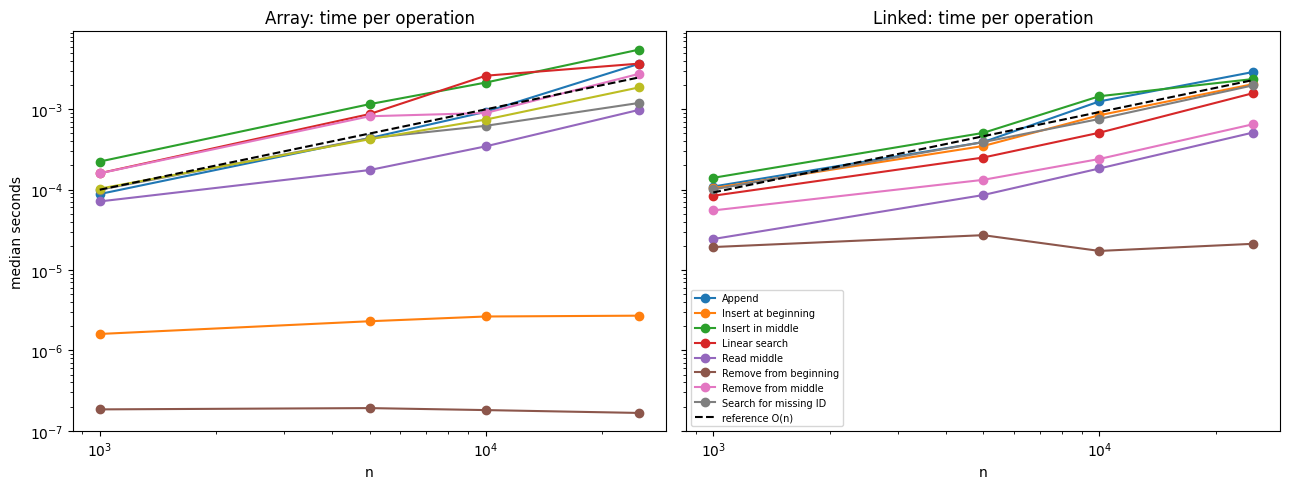

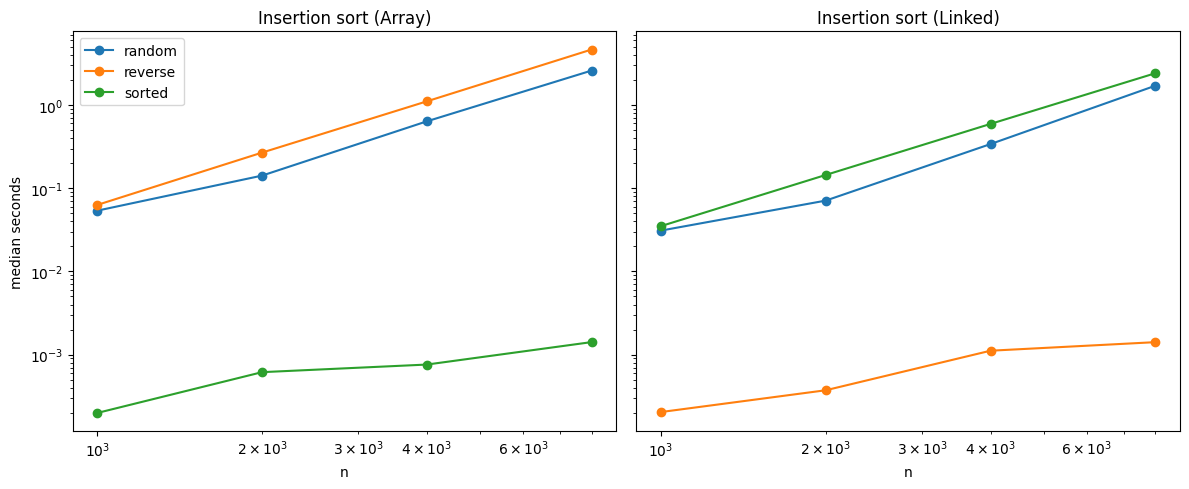

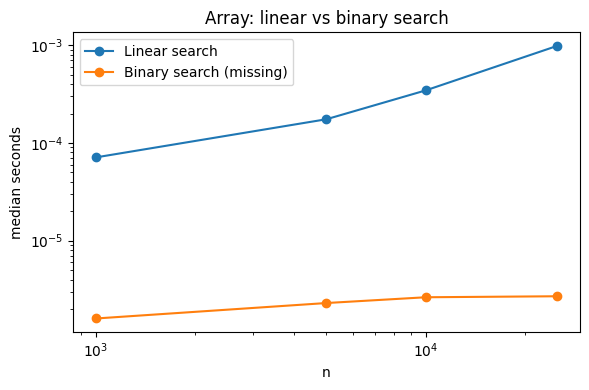

n                                  25k / 5k
operation               structure          
Append                  Array          8.43
                        Linked         7.45
Binary search (missing) Array          1.17
Insert at beginning     Array          4.78
                        Linked         5.89
Insert in middle        Array          4.24
                        Linked         4.68
Linear search           Array          5.62
                        Linked         6.32
Read middle             Array          0.87
                        Linked         5.99
Remove from beginning   Array          3.38
                        Linked         0.78
Remove from middle      Array          2.75
                        Linked         4.92
Search for missing ID   Array          4.43
                        Linked         5.08

n                  8k / 2k
input   structure         
random  Array        18.30
        Linked       24.00
reverse Array        17.33
        Linked        3.78
sorted  Array         2.30
        Linked       16.68

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, struct in zip(axes, ("Array", "Linked")):
    for name, g in ops_df[ops_df.structure == struct].groupby("operation"):
        ax.plot(g.n, g.seconds, marker="o", label=name)
    ref = ops_df[(ops_df.structure == struct) & (ops_df.n == SIZES[0])].seconds.median()
    ax.plot(SIZES, [ref * n / SIZES[0] for n in SIZES], "k--", label="reference O(n)")
    ax.set(xscale="log", yscale="log", title=f"{struct}: time per operation", xlabel="n")
axes[0].set_ylabel("median seconds")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, struct in zip(axes, ("Array", "Linked")):
    for kind, g in sort_df[sort_df.structure == struct].groupby("input"):
        ax.plot(g.n, g.seconds, marker="o", label=kind)
    ax.set(xscale="log", yscale="log", title=f"Insertion sort ({struct})", xlabel="n")
axes[0].set_ylabel("median seconds"); axes[0].legend(); plt.tight_layout(); plt.show()


fig, ax = plt.subplots(figsize=(6, 4))
for name in ("Linear search", "Binary search (missing)"):
    g = ops_df[(ops_df.operation == name) & (ops_df.structure == "Array")]
    ax.plot(g.n, g.seconds, marker="o", label=name)
ax.set(xscale="log", yscale="log", title="Array: linear vs binary search", xlabel="n", ylabel="median seconds")
ax.legend(); plt.tight_layout(); plt.show()


piv = ops_df.pivot_table(index=["operation", "structure"], columns="n", values="seconds")
piv["25k / 5k"] = piv[25_000] / piv[5_000]
spv = sort_df.pivot_table(index=["input", "structure"], columns="n", values="seconds")
spv["8k / 2k"] = spv[8_000] / spv[2_000]
display(piv[["25k / 5k"]].round(2)); display(spv[["8k / 2k"]].round(2))

## Observed vs. predicted

**Result that differed from my prediction:** (describe one specific result, with the numbers from the ratio table)

**Why:** (e.g., `append`/`push`/`insertAt` run an O(n) duplicate check before the O(1) work, so they scale linearly in both structures)

**Was the Big-O analysis still correct?** (Yes or no, and explain)

## Benchmarks vs. Big-O

Timing shows what happened on this machine, with this interpreter, at these sizes. Big-O explains how the amount of work grows with n. Constant factors (Python loops, pointer chasing, cache behavior) can reorder the structures at small n without changing the growth rate. The two are complementary, and neither replaces the other.

<h2> 11. Part H — Complexity Analysis

**1. Dynamic Array vs. Linked List**

| **Operation** | **Dynamic Array** | **Linked List**| **Explanation**|
|---|---|---|---|
|**Indexed access getAt()** | O(1)) | O(n) | Array reads the index directly. Linked list follows nodes from head to target. |
|**Search by ID (findById)** | O(n) | O(n) | Both compare IDs one by one. A missing ID requires checking all requests|
|**Push / prepend (push)** | O(n) | O(n) | Array checks duplicated and shifts requests right. Linked list checks duplicates, then updates head|
|**Append (append)** | O(n) | O(n) | Both scan for duplicate IDs. Array may resize. Linked list attached directly to end using tail.|
|**Insert at position (insertAt)** | O(n) | O(n) | Array checks for duplicated, shifts requests, and may resize. Linked list checks duplicates, traverses, then changes links.|
|**Remove at position (removeAt)** | O(n) | O(n) | Array shifts later requests left. Linked list traverses to the previous node, then updates the links|
|**Count (count)** | O(1) | O(1) | Both return the stored self.size. No traversal or counting loop needed|


**2. Searching and Sorting Algorithms**

|**Algorithm**| **Worst-Case Time** | **Extra Space** | **Explanation**|
|---|---|---|---|
|**Linear Search** | O(n) | O(1) | Checks IDs one by one and may examine all requests. Uses only a few variables to track the search. |
|**Binary Search** | O(log n) | O(1) | Checks the middle of a sorted array and cuts the search area in half each time. No extra array is needed. |
|**First-occurence Search** | O(log n) |O(1) |Uses binary search on sorted priorities. Keeps checking left to find the first match.|
|**Insertion Sort (array)**| O(n²) | O(1) | Compares and shifts requests until they are in priority order. Sorts within the same array.|
|**Insertion Sort (linked list)**| O(n²) | O(1) | Finds the correct place for each node and changes the links. No new list is created. |
|**Merge Sort (array)**| O(n log n) | O(n) | Splits the requetss into smaller groups, then merges them in time order. Uses a temporary array.|
|**Merge Sort (linked list)**| O(n log n) | O(log n) | Splits the linked list and merges nodes in time order. Uses memory for recursive calls. |


**3. Insertion Sort - Best, Average, and Worst Cases**

|**Structure**| **Case** | **Time**| **Explanation**|
|---|---|---|---|
|**Array** | Best | O(n) | Already sorted at start. Each request is checked, but nothing needs shifting. |
|**Array** | Average | O(n²) | Mixed order at the start. Some requests need several comparisons and shifts.|
|**Array** | Worst | O(n²) | Reverse order at start. Each request must be shifted before earlier requests. |
|**Linked List**| Best | O(n) | Reverse order at start, Each node is added to the front of the chain. |
|**Linked List**| Average | O(n²) | Mixed order at start. Find each nodes position requires scanning the chain. |
|**Linked List**| Worst | O(n²) | Already sorted at start. Each node must be placed at the end of the growing sorted chain.|


**4. Additional Cost Explanations**

Some methods perform more than one operation. Our group considered each cost seperately when deciding the overall time complexity. Here is the breakdown of this:

*   **Duplicate ID checks:** Both the array and the linked list check for cuplicate IDs before adding a request. This requires searching through up to n requests, taking O(n) time. Because of this, even append() takes O(n) time in our implmentations.

*   **Array Shifting:** The arrays push() and insertAt() may shift requests to make more room. removeAt() may shift requests left to close the gap. Shifting can take O(n) time.

*   **Linked list traveral and link changes:** This linked list may need to walk through nodes to reach a position, taking O(n) time. Once the correct position is found, changing the links takes O(1) time. Traveral is teh larher cost in this case.

*   **Array resizing:** When the array is full, _resize() creates a larger array and copies the existing requests. This takes O(n) time and O(n) extra space. When resiizing is not needed, insertion would use O(1) extra space instead.

*   **Searching:** Linear search checks requests one by one, taking O(n) time. Binary search cuts the search range roughly in half each step, taking O(log n) time when the array is sorted.

*   **Sorting:** Insertion sort can take O(n²) time because requests may need repeated comparisons, shifts, or node traversal. Merge sort takes O(n log n) time because it repeatedly splits and merges the requests. Array merge sorts uses O(n) temporary space, while linked list merge sort uses O(log n) space for recursive calling.

*   **Overall complexity - keep dominant term:** When a method has multiple costs, we add them and keep the largest growing term. For example, an insertion that checks duplicates, shifts requests, and stores the new request has a time complexity like this:

O(n) + O(n) + O(1). We need O(n) as the dominant term because they grow with the number or requests.












